# Does opt_einsum help these compressed models?

The BlockTT classifier combines an input with three tensor cores through one
`torch.einsum` call. A **contraction path** is the order in which those tensors
are multiplied together. Different orders can change both work and rounding.

We compare PyTorch's opt_einsum integration **disabled** against **enabled with
strategy `"auto"`**, using the same model objects and stored weights. We ask
whether the classifier becomes faster and whether any change is visible for
the complete ResNet-18. Dense inference is a control: it contains no einsum
operation that should benefit from this flag.

This notebook runs the comparison. It uses synthetic inputs for agreement and
timing, without measuring task accuracy, training, or runtime memory. The
existing notebook and historical results are separate and remain unchanged.

## 1. Set up the comparison and inputs

Use the separate **TensorLy opt_einsum comparison** kernel from the README.
Its Python and package versions match the original notebook environment, with
opt_einsum 3.4.0 added. Installing this optional package in the original environment
could silently enable PyTorch's integration, so we keep the environments separate.

The CPU setup is float32, four PyTorch threads and one inter-op thread. The
whole-model input is one seeded RGB tensor shaped `(1, 3, 224, 224)`. Cached
pretrained weights are reused; no dataset or weight download occurs here.
Save edits before execution so the code fingerprint describes this run.

In [1]:
import csv
import hashlib
import importlib.metadata
import json
import os
from pathlib import Path
import statistics
import sys
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import opt_einsum
import torch
import torch.backends.opt_einsum as torch_opt_einsum
import tensorly as tl
from tensorly import tenalg, plugins
from IPython.display import Markdown, display

repository = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "tltorch").is_dir())
sys.path.insert(0, str(repository))
from tltorch import compress_model
import tltorch
from examples.model_compression import experiment
from examples.model_compression import opt_einsum_comparison as comparison

example_directory = repository / "examples/model_compression"
output_directory = example_directory / "results/opt_einsum_run_001"
if output_directory.exists():
    raise FileExistsError(f"Choose a new results directory: {output_directory}")
cache_directory = Path.home() / ".cache/tltorch-model-compression"
os.environ.setdefault("TORCH_HOME", str(cache_directory / "torch"))
assert Path(tltorch.__file__).resolve() == repository / "tltorch/__init__.py"

def show_table(columns, rows):
    lines = [" | ".join(columns), " | ".join("---" for _ in columns)]
    lines.extend(" | ".join(str(value) for value in row) for row in rows)
    display(Markdown("\n".join(lines)))


In [2]:
settings = {"device": "cpu", "dtype": "float32", "threads": 4, "interop_threads": 1,
            "seed": 2026, "input_seed": 2027, "rounds": 4, "warmup": 20, "repeats": 100,
            "batch_size": 1, "rtol": 1e-4, "atol": 1e-5}
device = experiment.configure_runtime(settings["device"], settings["threads"])
inputs = torch.randn(1, 3, 224, 224, dtype=torch.float32, device=device,
                     generator=torch.Generator(device=device).manual_seed(settings["input_seed"]))
caller_settings = comparison.backend_settings()
assert caller_settings["available"]
assert tl.get_backend() == "pytorch" and tenalg.get_backend() == "core"
assert caller_settings["tensorly_default_einsum"] and caller_settings["tensorly_plugin_inactive"]
assert caller_settings["tensorly_plugin_cache_entries"] == 0
assert torch.get_num_interop_threads() == settings["interop_threads"]

environment = experiment.environment_info()
environment["python_executable"] = sys.executable
environment["packages"] = {distribution.metadata["Name"]: distribution.version
                           for distribution in importlib.metadata.distributions()}
notebook_path = example_directory / "opt_einsum_comparison.ipynb"
notebook_on_disk = json.loads(notebook_path.read_text())
notebook_code = "\n\n".join("".join(cell["source"]) for cell in notebook_on_disk["cells"]
                            if cell["cell_type"] == "code")
environment["notebook_code_sha256"] = hashlib.sha256(notebook_code.encode()).hexdigest()
environment["comparison_helper_sha256"] = experiment.file_sha256(comparison.__file__)
environment["requirements_sha256"] = experiment.file_sha256(example_directory / "requirements-opt-einsum.txt")
print("Environment:", sys.executable)
print("opt_einsum:", opt_einsum.__version__)
print("Hardware:", environment["cpu"])
print("Actual initial settings:", caller_settings)


Environment: /home/rafael_magaldi/.cache/tltorch-model-compression/venv-opt-einsum/bin/python
opt_einsum: 3.4.0
Hardware: Intel(R) Core(TM) Ultra 9 285H
Actual initial settings: {'available': True, 'enabled': True, 'strategy': 'auto', 'tensorly_backend': 'pytorch', 'tensorly_tenalg_backend': 'core', 'tensorly_default_einsum': True, 'tensorly_plugin_inactive': True, 'tensorly_plugin_cache_entries': 0, 'threads': 4, 'interop_threads': 1, 'matmul_precision': 'highest', 'deterministic_algorithms': True, 'mkldnn_enabled': True, 'autocast_enabled': False}


The two conditions change only `torch.backends.opt_einsum.enabled`. Both use
strategy `"auto"`; it is ignored while disabled. The helper's context manager
sets these flags explicitly and restores their previous values even if a call
fails. TensorLy stays on its PyTorch / `core` backends; its separate cached
opt_einsum plugin remains inactive.

PyTorch's installed implementation calls `opt_einsum.contract_path` on each
eligible forward. Our timed enabled condition includes that path-selection
cost; this is not a cached-path comparison.

In [3]:
conditions = {"disabled": False, "auto": True}
condition_settings = {}
for name, enabled in conditions.items():
    with comparison.execution_mode(enabled):
        condition_settings[name] = comparison.backend_settings()
print(json.dumps(condition_settings, indent=2))
assert comparison.backend_settings() == caller_settings


{
  "disabled": {
    "available": true,
    "enabled": false,
    "strategy": "auto",
    "tensorly_backend": "pytorch",
    "tensorly_tenalg_backend": "core",
    "tensorly_default_einsum": true,
    "tensorly_plugin_inactive": true,
    "tensorly_plugin_cache_entries": 0,
    "threads": 4,
    "interop_threads": 1,
    "matmul_precision": "highest",
    "deterministic_algorithms": true,
    "mkldnn_enabled": true,
    "autocast_enabled": false
  },
  "auto": {
    "available": true,
    "enabled": true,
    "strategy": "auto",
    "tensorly_backend": "pytorch",
    "tensorly_tenalg_backend": "core",
    "tensorly_default_einsum": true,
    "tensorly_plugin_inactive": true,
    "tensorly_plugin_cache_entries": 0,
    "threads": 4,
    "interop_threads": 1,
    "matmul_precision": "highest",
    "deterministic_algorithms": true,
    "mkldnn_enabled": true,
    "autocast_enabled": false
  }
}


## 2. Build the three models once

The dense baseline is torchvision ResNet-18 with `ResNet18_Weights.IMAGENET1K_V1`.
We explicitly disable the integration during loading and every conversion,
keeping decomposition separate from the inference setting being studied.
Construction stays outside inference mode.

Each compressed copy starts from the same dense baseline. Tucker compresses the
two convolutional kernels while keeping their spatial ranks at 3×3. BlockTT
splits the classifier's 512 inputs and 1,000 outputs into three paired modes.
Targets 0.75 and 0.50 describe approximate retained weight parameters in each
selected layer, not whole-model savings.

In [4]:
construction_settings = None
with comparison.execution_mode(False):
    construction_settings = comparison.backend_settings()
    torch.manual_seed(settings["seed"])
    baseline, preprocessing = experiment.load_baseline(device, allow_download=False)
baseline_fingerprint = experiment.model_fingerprint(baseline)
models = {"dense": baseline}
reports = {}
layers_by_variant = {}

for name, fraction in (("fraction_0.75", 0.75), ("fraction_0.50", 0.50)):
    layers = {
        "layer4.0.conv2": {"factorization": "Tucker", "rank": fraction, "fixed_rank_modes": "spatial"},
        "layer4.1.conv2": {"factorization": "Tucker", "rank": fraction, "fixed_rank_modes": "spatial"},
        "fc": {"factorization": "BlockTT", "rank": fraction,
               "in_tensorized_features": (8, 8, 8), "out_tensorized_features": (10, 10, 10)},
    }
    with comparison.execution_mode(False):
        torch.manual_seed(settings["seed"])
        models[name], reports[name] = compress_model(baseline, layers, implementation="factorized")
    layers_by_variant[name] = layers
    assert experiment.model_fingerprint(baseline) == baseline_fingerprint
    print(name, "actual ranks:", [layer["actual_rank"] for layer in reports[name]["replacements"]])

model_fingerprints_before = {name: experiment.model_fingerprint(model) for name, model in models.items()}
model_ids = {name: id(model) for name, model in models.items()}
assert all(not module.training for model in models.values() for module in model.modules())
assert comparison.backend_settings() == caller_settings


fraction_0.75 actual ranks: [(390, 390, 3, 3), (390, 390, 3, 3), (1, 68, 68, 1)]


fraction_0.50 actual ranks: [(310, 310, 3, 3), (310, 310, 3, 3), (1, 56, 56, 1)]


## 3. Check agreement before timing

For each model, capture its classifier's `(1, 512)` input once from an untimed
forward with the integration disabled. The same captured features are reused
under both settings. Whole-model calls reuse the same seeded image tensor.

We require `torch.testing.assert_close` with **rtol=1e-4 and atol=1e-5**: each
output difference must fit `1e-5 + 1e-4 × abs(disabled_output)`. The absolute
allowance covers values near zero; the relative allowance permits small float32
rounding differences when multiplication order changes. These tolerances are
fixed before execution. A failure stops the notebook before timing.

This checks two execution methods on fixed inputs. It does not establish
ImageNet accuracy or agreement for every possible input.

In [5]:
features = {name: comparison.classifier_features(model, inputs) for name, model in models.items()}
assert all(tuple(feature.shape) == (1, 512) for feature in features.values())
feature_hashes_before = {name: hashlib.sha256(feature.numpy().tobytes()).hexdigest()
                         for name, feature in features.items()}
agreement = {}
for name, model in models.items():
    agreement[name] = {}
    for scope, module, data in (("classifier", model.fc, features[name]), ("whole_model", model, inputs)):
        agreement[name][scope] = comparison.compare_outputs(
            module, data, rtol=settings["rtol"], atol=settings["atol"])
show_table(["Model", "Scope", "Maximum absolute output difference"],
           [[name, scope, f"{result['max_absolute_difference']:.9g}"]
            for name, scopes in agreement.items() for scope, result in scopes.items()])
assert {name: experiment.model_fingerprint(model) for name, model in models.items()} == model_fingerprints_before


Model | Scope | Maximum absolute output difference
--- | --- | ---
dense | classifier | 0
dense | whole_model | 0
fraction_0.75 | classifier | 1.43051147e-06
fraction_0.75 | whole_model | 1.43051147e-06
fraction_0.50 | classifier | 9.53674316e-07
fraction_0.50 | whole_model | 9.53674316e-07

We also verify actual use, rather than assuming installation enables optimization.
For each BlockTT classifier, a temporary wrapper counts calls to
`opt_einsum.contract_path` during one disabled and one enabled forward. The expected
counts are zero and one. It records the equation, operand shapes, and strategy.
The wrapper is removed before any timing, including if the check fails.
The Tucker convolutions use convolutions and matrix products, so this integration
does not optimize their forward path.

In [6]:
optimizer_use = {name: comparison.verify_optimizer_use(models[name].fc, features[name])
                 for name in layers_by_variant}
for name, checks in optimizer_use.items():
    print(name, [(check["enabled"], len(check["calls"])) for check in checks])
    print("Enabled call:", checks[1]["calls"][0])
assert comparison.backend_settings() == caller_settings


fraction_0.75 [(False, 0), (True, 1)]
Enabled call: {'equation': 'abcd,hebi,ifcj,jgdk->aefg', 'operand_shapes': [[1, 8, 8, 8], [1, 10, 8, 68], [68, 10, 8, 68], [68, 10, 8, 1]], 'strategy': 'auto'}
fraction_0.50 [(False, 0), (True, 1)]
Enabled call: {'equation': 'abcd,hebi,ifcj,jgdk->aefg', 'operand_shapes': [[1, 8, 8, 8], [1, 10, 8, 56], [56, 10, 8, 56], [56, 10, 8, 1]], 'strategy': 'auto'}


## 4. Measure paired classifier and whole-model latency

All three models are already built and stay resident. For each model and scope,
measure disabled and auto next to each other. There are **four rounds in one
process**: disabled→auto in rounds 1 and 3, auto→disabled in rounds 2 and 4.
The model order rotates each round. These changes reduce dependence on always
measuring one condition first; they do not control CPU frequency or other activity.

Every block uses evaluation/inference mode, **20 warm-ups and 100 measured passes**.
The existing timing helper measures completed forwards in milliseconds per batch
of one. Loading, conversion, feature capture, flag changes, correctness checks,
and tracing are outside the timer. Parameter/buffer hashes are checked after each
round, outside the paired blocks. No accuracy evaluation runs here.

In [7]:
blocks = comparison.measure_rounds(models, features, inputs, rounds=settings["rounds"],
                                   warmup=settings["warmup"], repeats=settings["repeats"])
rows = comparison.paired_results(blocks)
model_fingerprints_after = {name: experiment.model_fingerprint(model) for name, model in models.items()}
feature_hashes_after = {name: hashlib.sha256(feature.numpy().tobytes()).hexdigest()
                        for name, feature in features.items()}
assert model_fingerprints_after == model_fingerprints_before
assert feature_hashes_after == feature_hashes_before
assert {name: id(model) for name, model in models.items()} == model_ids
assert comparison.backend_settings() == caller_settings
print("All model and feature values are unchanged; caller settings restored.")


Round 1: dense, classifier pair complete


Round 1: dense, whole_model pair complete


Round 1: fraction_0.75, classifier pair complete


Round 1: fraction_0.75, whole_model pair complete


Round 1: fraction_0.50, classifier pair complete


...

Round 4: fraction_0.75, classifier pair complete


Round 4: fraction_0.75, whole_model pair complete


Round 4: fraction_0.50, classifier pair complete


Round 4: fraction_0.50, whole_model pair complete


All model and feature values are unchanged; caller settings restored.


## 5. Read every round and compare the two scopes

Each row is one adjacent disabled/auto pair. Brackets show the 25th and 75th
percentiles of its 100 samples, not confidence intervals across rounds.
**Speedup = disabled median / auto median**: above 1 means auto is faster;
below 1 means it is slower. Dense controls help reveal ordinary timing variation.
No samples are pooled and no fastest round is selected.

In [8]:
for scope in ("classifier", "whole_model"):
    display(Markdown(f"**{scope.replace('_', ' ').title()} — milliseconds per batch of one**"))
    show_table(["Round", "Model", "First", "Disabled median [p25, p75]", "Auto median [p25, p75]", "Speedup"],
               [[row["round"], row["model"], row["first_condition"],
                 f"{row['disabled_median_ms']:.4f} [{row['disabled_p25_ms']:.4f}, {row['disabled_p75_ms']:.4f}]",
                 f"{row['auto_median_ms']:.4f} [{row['auto_p25_ms']:.4f}, {row['auto_p75_ms']:.4f}]",
                 f"{row['speedup']:.3f}×"] for row in rows if row["scope"] == scope])


**Classifier — milliseconds per batch of one**

Round | Model | First | Disabled median [p25, p75] | Auto median [p25, p75] | Speedup
--- | --- | --- | --- | --- | ---
1 | dense | disabled | 0.0194 [0.0192, 0.0196] | 0.0192 [0.0191, 0.0194] | 1.010×
1 | fraction_0.75 | disabled | 0.4926 [0.4857, 0.4992] | 0.8145 [0.8008, 0.8275] | 0.605×
1 | fraction_0.50 | disabled | 0.3765 [0.3704, 0.3788] | 0.6708 [0.6635, 0.6812] | 0.561×
2 | fraction_0.75 | auto | 0.4888 [0.4831, 0.4972] | 0.8247 [0.8112, 0.8329] | 0.593×
2 | fraction_0.50 | auto | 0.3660 [0.3643, 0.3687] | 0.6740 [0.6660, 0.6870] | 0.543×
2 | dense | auto | 0.0167 [0.0166, 0.0169] | 0.0169 [0.0167, 0.0171] | 0.990×
3 | fraction_0.50 | disabled | 0.3668 [0.3647, 0.3690] | 0.6690 [0.6623, 0.6789] | 0.548×
3 | dense | disabled | 0.0167 [0.0165, 0.0168] | 0.0166 [0.0165, 0.0168] | 1.002×
3 | fraction_0.75 | disabled | 0.4829 [0.4796, 0.4858] | 0.7996 [0.7920, 0.8107] | 0.604×
4 | dense | auto | 0.0168 [0.0167, 0.0170] | 0.0172 [0.0170, 0.0174] | 0.980×
4 | fraction_0.75 | auto | 0.4823 [0.4792, 0.4854] | 0.8117 [0.8026, 0.8197] | 0.594×
4 | fraction_0.50 | auto | 0.3675 [0.3641, 0.3728] | 0.6630 [0.6587, 0.6729] | 0.554×

**Whole Model — milliseconds per batch of one**

Round | Model | First | Disabled median [p25, p75] | Auto median [p25, p75] | Speedup
--- | --- | --- | --- | --- | ---
1 | dense | disabled | 20.7662 [20.6485, 20.8595] | 20.8194 [20.7121, 20.9140] | 0.997×
1 | fraction_0.75 | disabled | 25.2309 [25.0282, 25.4322] | 25.7722 [25.5918, 26.0247] | 0.979×
1 | fraction_0.50 | disabled | 23.4653 [23.2243, 23.6676] | 23.9847 [23.7956, 24.1303] | 0.978×
2 | fraction_0.75 | auto | 25.0451 [24.8972, 25.3058] | 25.6492 [25.4715, 25.8211] | 0.976×
2 | fraction_0.50 | auto | 23.2910 [23.1710, 23.4422] | 23.9056 [23.6721, 24.0997] | 0.974×
2 | dense | auto | 20.7161 [20.5361, 20.8405] | 20.7020 [20.6130, 20.7989] | 1.001×
3 | fraction_0.50 | disabled | 23.1775 [23.0722, 23.3346] | 23.7204 [23.6284, 23.8508] | 0.977×
3 | dense | disabled | 20.6751 [20.5806, 20.8165] | 20.7900 [20.6876, 20.9410] | 0.994×
3 | fraction_0.75 | disabled | 24.9532 [24.8182, 25.1493] | 25.5989 [25.4062, 25.7358] | 0.975×
4 | dense | auto | 20.6940 [20.5984, 20.8131] | 20.7160 [20.6372, 20.8122] | 0.999×
4 | fraction_0.75 | auto | 25.0406 [24.8960, 25.2087] | 25.5765 [25.4673, 25.7870] | 0.979×
4 | fraction_0.50 | auto | 23.1305 [22.9951, 23.2420] | 23.6431 [23.5193, 23.8060] | 0.978×

The two plot panels keep classifier and complete-model effects separate.
Every point is one round's ratio of medians; the horizontal line marks equal
latency. The optional summary below takes the median of the **four ratios**
and shows their range. It does not replace the per-round timings above.

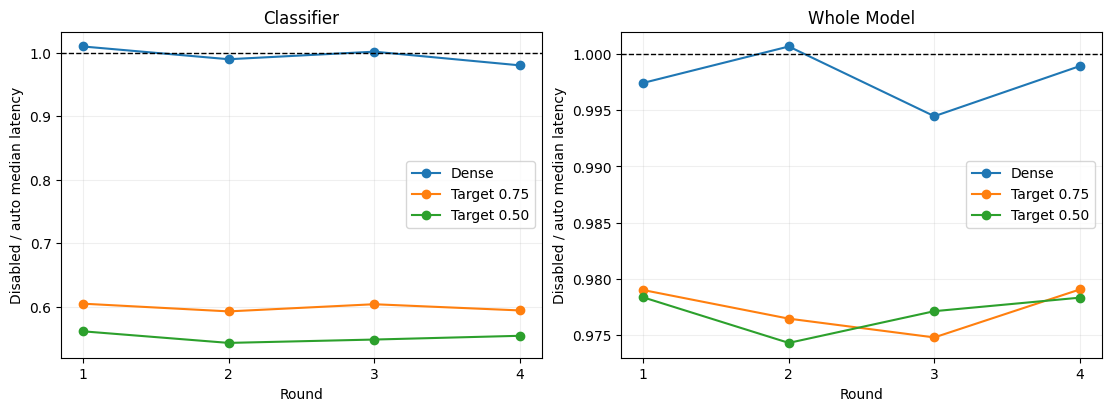

dense, classifier: median ratio 0.996×; range 0.980–1.010×
dense, whole_model: median ratio 0.998×; range 0.994–1.001×
fraction_0.75, classifier: median ratio 0.599×; range 0.593–0.605×
fraction_0.75, whole_model: median ratio 0.978×; range 0.975–0.979×
fraction_0.50, classifier: median ratio 0.551×; range 0.543–0.561×
fraction_0.50, whole_model: median ratio 0.978×; range 0.974–0.978×


In [9]:
labels = {"dense": "Dense", "fraction_0.75": "Target 0.75", "fraction_0.50": "Target 0.50"}
figure, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for axis, scope in zip(axes, ("classifier", "whole_model")):
    for name in models:
        selected = sorted((row for row in rows if row["model"] == name and row["scope"] == scope),
                          key=lambda row: row["round"])
        axis.plot([row["round"] for row in selected], [row["speedup"] for row in selected],
                  marker="o", label=labels[name])
    axis.axhline(1, color="black", linestyle="--", linewidth=1)
    axis.set_title(scope.replace("_", " ").title())
    axis.set_xlabel("Round")
    axis.set_ylabel("Disabled / auto median latency")
    axis.set_xticks(range(1, settings["rounds"] + 1))
    axis.grid(alpha=0.2)
    axis.legend()
plt.show()

for name in models:
    for scope in ("classifier", "whole_model"):
        ratios = [row["speedup"] for row in rows if row["model"] == name and row["scope"] == scope]
        print(f"{name}, {scope}: median ratio {statistics.median(ratios):.3f}×; "
              f"range {min(ratios):.3f}–{max(ratios):.3f}×")


## 6. Interpret this run

The written observations in this notebook describe the saved run in
`results/opt_einsum_run_001/`. Rerunning the cells updates tables and plots,
but does not update these observations. Review them separately against any
new results before drawing conclusions.

**Auto was slower in every compressed-model pair.** For the 0.75 classifier,
disabled medians were 0.482–0.493 ms and auto medians were 0.800–0.825 ms:
**65–69% longer** with auto. For the 0.50 classifier they were 0.366–0.376 ms
and 0.663–0.674 ms: **78–84% longer**. The median of four speedup ratios was
0.599× and 0.551×, respectively. This agrees across both condition orders.

The effect remained visible but was much smaller in the complete models.
Every compressed whole-model pair was **2.1–2.6% slower** with auto, with median
speedup ratios near 0.978× for both targets. Most work happens outside the
classifier; Tucker's convolution path does not use this einsum integration.

Dense controls also varied. Their classifier speedup ratios ranged from
0.980× to 1.010×, and whole-model ratios from 0.994× to 1.001×. The dense
classifier fell from about 0.019 ms in round 1 to about 0.017 ms later.
These changes show ordinary timing variation, but they are much smaller than
the compressed classifier slowdown. The whole-model effect is small, although
its direction was consistent in all eight compressed-model pairs. Quartiles
within a block do not establish confidence across machines or fresh processes.

The enabled timings include a new path search on each forward. That overhead
and the chosen multiplication order are both part of this condition; this
experiment does not measure their costs separately, so it cannot assign the
slowdown to one cause. No cached-plugin or strategy comparison was performed.

**Recommendation:** keep the integration disabled for this main experiment's
current batch-one CPU configuration. Installing opt_einsum is not a speed benefit
here. If a future environment contains it, set the flag explicitly so installation
does not silently change execution. The original experiment has not been modified.

All output checks passed with the predeclared tolerance. Maximum differences
were 1.43e-6 for target 0.75, 9.54e-7 for target 0.50, and zero for dense,
in both scopes. Ranks, parameter counts, and stored parameter/buffer values were
unchanged. This experiment measures neither task accuracy nor runtime memory.
It does not establish behavior for different ranks, batches, devices, or software,
and it does not resolve the historical CPU timing discrepancy.

## 7. Save the evidence

Keep every block's raw samples, the output-agreement checks, verified optimizer
calls, conversion reports, and actual runtime flags. The configuration includes
seeds, hardware, complete package versions, code hashes, and fingerprints before
and after the comparison. The new directory is never allowed to overwrite an
existing run. Save the executed notebook too, so colleagues can read its outputs.

In [10]:
from torchvision.models import ResNet18_Weights
weights = ResNet18_Weights.IMAGENET1K_V1
weight_file = Path(torch.hub.get_dir()) / "checkpoints" / weights.url.rsplit("/", 1)[-1]
configuration = {
    "purpose": "Synthetic-input execution and timing comparison; no new task-accuracy or runtime-memory measurement",
    "settings": settings, "environment": environment,
    "weights": {"identifier": "ResNet18_Weights.IMAGENET1K_V1", "url": weights.url,
                "sha256": experiment.file_sha256(weight_file)},
    "model": "torchvision.resnet18", "implementation": "factorized", "layers": layers_by_variant,
    "whole_model_input_shape": list(inputs.shape), "classifier_input_shape": [1, 512],
    "input_sha256": hashlib.sha256(inputs.numpy().tobytes()).hexdigest(),
    "feature_hashes_before": feature_hashes_before, "feature_hashes_after": feature_hashes_after,
    "model_fingerprints_before": model_fingerprints_before, "model_fingerprints_after": model_fingerprints_after,
    "construction_backend": construction_settings, "conditions": condition_settings,
    "caller_settings_before": caller_settings, "caller_settings_after": comparison.backend_settings(),
    "timing_units": "milliseconds per batch of one", "summary": "Per-pair medians; speedup = disabled / auto",
    "path_selection": "PyTorch auto searches on each eligible forward; no TensorLy plugin or path cache",
    "completed_utc": datetime.now(timezone.utc).isoformat(),
}
output_directory.mkdir(parents=True, exist_ok=False)
with (output_directory / "results.csv").open("w", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(rows[0]), lineterminator="\n")
    writer.writeheader()
    for row in rows:
        writer.writerow({key: f"{value:.6f}" if isinstance(value, float) else value for key, value in row.items()})
for filename, contents in {"configuration.json": configuration, "timing_blocks.json": blocks,
                           "output_agreement.json": agreement, "optimizer_use.json": optimizer_use,
                           "compression_reports.json": reports}.items():
    (output_directory / filename).write_text(json.dumps(contents, indent=2, allow_nan=False) + "\n")
figure.savefig(output_directory / "comparison.png", dpi=160, bbox_inches="tight")
print("Saved all rounds to:", output_directory)


Saved all rounds to: /home/rafael_magaldi/Documents/infq-tensorly-torch-model-compression/examples/model_compression/results/opt_einsum_run_001
